# 04 · Validation analysis: leaderboard, errors, feature drivers
Everything here uses **validation only** (2018-07 to 2018-12). It ends by freezing the model configurations,
which is the last step before 2019 is touched (Gate G2).

In [1]:
import sys, os, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
from src import evaluate as ev, metrics as M, models as mo
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "axes.titleweight": "bold"})
def savefig(fig, name):
    fig.tight_layout(); fig.savefig(ev.FIGS / f"{name}.png", dpi=150); plt.show()
print("results folder:", ev.RESULTS, "| smoke mode:", mo.SMOKE, "| threads:", mo.N_JOBS)

results folder: C:\dev\traffic-prediction\results | smoke mode: False | threads: 11


## 1. Validation leaderboard (all models, both horizons)

In [2]:
NAMES = {n: mo.LABEL[n] for n in mo.MODELS}
boards = {}
for h in ev.HORIZONS:
    lb = ev.leaderboard("val", h)
    bb = lb.attrs["best_baseline"]
    va = ev.load_table(h, ["val"])
    bt = ev.baseline_table(va)
    lb = lb.rename(index=NAMES)
    lb["Skill"] = lb["Skill"].astype(float)
    boards[h] = lb
    print(f"\n=== Horizon {h} min   (best baseline on validation: {bb}, MAE {bt.loc[bb, 'MAE']:.2f}) ===")
    display(lb.drop(columns="n").round(3))
    lb.to_csv(ev.RESULTS / f"val_leaderboard_h{h}.csv")


=== Horizon 15 min   (best baseline on validation: Persistence, MAE 66.19) ===


,MAE,RMSE,WAPE,Skill
Model,,,,
LightGBM,47.967,78.190,0.054,0.275
XGBoost,48.060,78.288,0.054,0.274
CatBoost,48.504,78.367,0.055,0.267
Random Forest,49.286,80.163,0.055,0.255
AdaBoost,51.298,81.673,0.058,0.225
Gradient Boosting,51.372,80.936,0.058,0.224
Decision Tree,52.312,83.411,0.059,0.210
Ridge,57.359,87.317,0.064,0.133
PCA + Ridge,57.359,87.317,0.064,0.133



=== Horizon 60 min   (best baseline on validation: 4-week average, MAE 89.18) ===


,MAE,RMSE,WAPE,Skill
Model,,,,
LightGBM,62.000,100.479,0.070,0.305
XGBoost,62.145,100.764,0.070,0.303
CatBoost,62.801,100.665,0.071,0.296
Random Forest,65.014,104.803,0.073,0.271
Gradient Boosting,67.979,106.596,0.076,0.238
AdaBoost,69.092,108.708,0.078,0.225
Decision Tree,70.056,111.484,0.079,0.214
Ridge,80.491,122.604,0.091,0.097
PCA + Ridge,80.491,122.604,0.091,0.097


### 1b. Validation leaderboard on clean rows only (repeated-template days removed)

In [3]:
for h in ev.HORIZONS:
    lbc = ev.leaderboard("val", h, clean=True).rename(index=NAMES)
    print(f"\n=== Horizon {h} min, clean rows ===")
    display(lbc.drop(columns="n").round(3))
    lbc.to_csv(ev.RESULTS / f"val_leaderboard_clean_h{h}.csv")


=== Horizon 15 min, clean rows ===


,MAE,RMSE,WAPE,Skill
Model,,,,
LightGBM,53.223,83.017,0.059,0.243
XGBoost,53.308,83.123,0.059,0.242
CatBoost,53.574,83.168,0.059,0.238
Random Forest,54.916,85.090,0.061,0.219
Gradient Boosting,56.265,85.726,0.062,0.200
AdaBoost,56.545,86.576,0.063,0.196
Decision Tree,57.878,88.448,0.064,0.177
Ridge,61.417,91.929,0.068,0.127
PCA + Ridge,61.417,91.929,0.068,0.127



=== Horizon 60 min, clean rows ===


,MAE,RMSE,WAPE,Skill
Model,,,,
LightGBM,67.976,106.036,0.075,0.296
XGBoost,68.183,106.396,0.075,0.294
CatBoost,68.602,106.202,0.076,0.290
Random Forest,71.582,110.387,0.079,0.259
Gradient Boosting,73.742,112.074,0.082,0.237
AdaBoost,75.158,114.199,0.083,0.222
Decision Tree,76.537,117.215,0.085,0.208
Ridge,85.221,127.992,0.094,0.118
PCA + Ridge,85.221,127.992,0.094,0.118


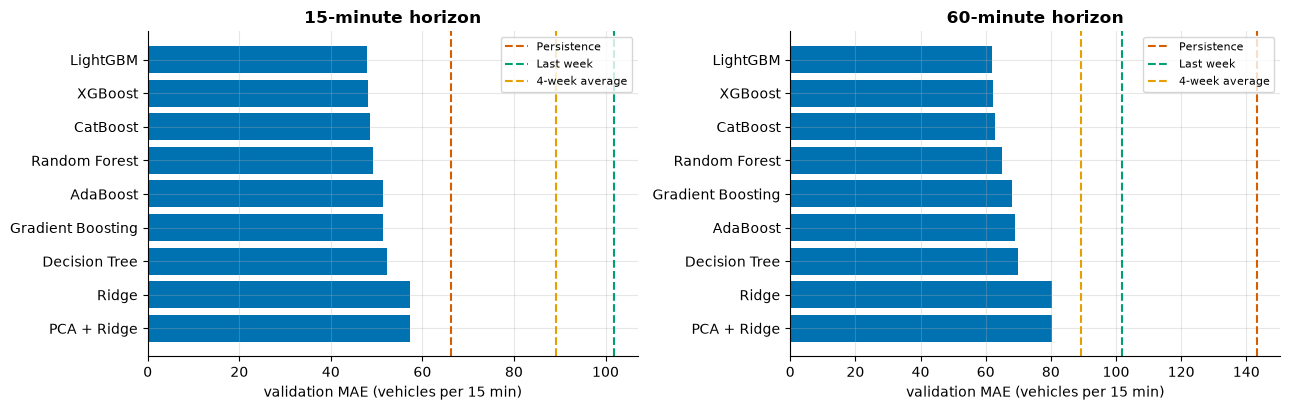

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, h in zip(axes, ev.HORIZONS):
    lb = boards[h].sort_values("MAE", ascending=False)
    base = ev.baseline_table(ev.load_table(h, ["val"]))
    ax.barh(lb.index, lb["MAE"], color="#0072B2")
    for i, name in enumerate(base.index):
        ax.axvline(base.loc[name, "MAE"], color=["#D55E00", "#009E73", "#E69F00"][i], ls="--", label=name)
    ax.set_xlabel("validation MAE (vehicles per 15 min)"); ax.set_title(f"{h}-minute horizon"); ax.legend(fontsize=8)
savefig(fig, "val_leaderboard")

## 2. When does each model win? Error by hour of day
Best model vs the best baseline, weekdays only, validation.

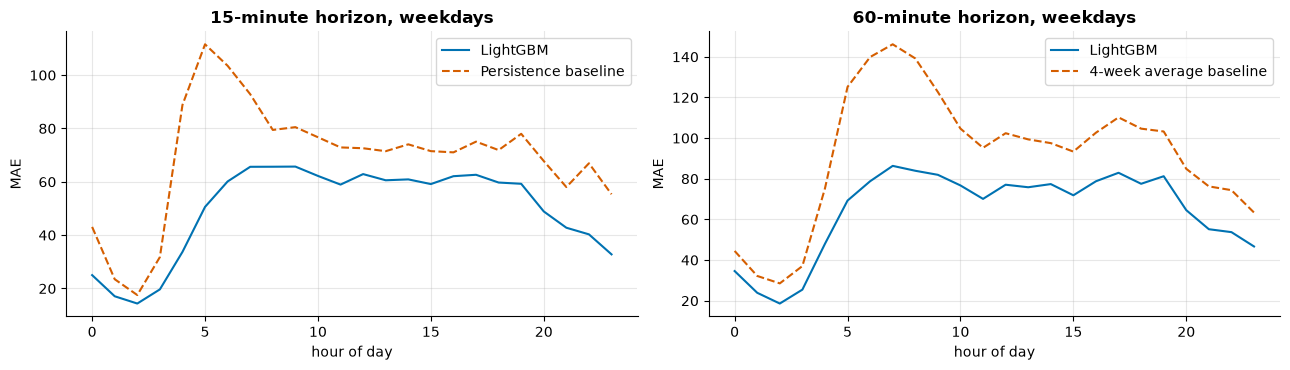

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=False)
for ax, h in zip(axes, ev.HORIZONS):
    top = boards[h].index[0]; key = [k for k, v in NAMES.items() if v == top][0]
    d = ev.load_preds("val", key, h); d = d[d["is_weekend"] == 0]
    bb = ev.best_baseline(ev.load_table(h, ["val"]))
    d["base"] = d[ev.BASELINES[bb]] * d["sc"]
    hr = d["target_time"].dt.hour
    ax.plot(d.groupby(hr).apply(lambda x: (x["y_raw"] - x["pred"]).abs().mean()), color="#0072B2", label=top)
    ax.plot(d.groupby(hr).apply(lambda x: (x["y_raw"] - x["base"]).abs().mean()), color="#D55E00", ls="--", label=f"{bb} baseline")
    ax.set_xlabel("hour of day"); ax.set_ylabel("MAE"); ax.set_title(f"{h}-minute horizon, weekdays"); ax.legend()
savefig(fig, "val_error_by_hour")

## 3. Residual diagnostics of the best model
Left: predicted vs actual (should hug the diagonal). Right: error grows with flow level, and its distribution has a
heavy tail (a few large misses, e.g. incidents).

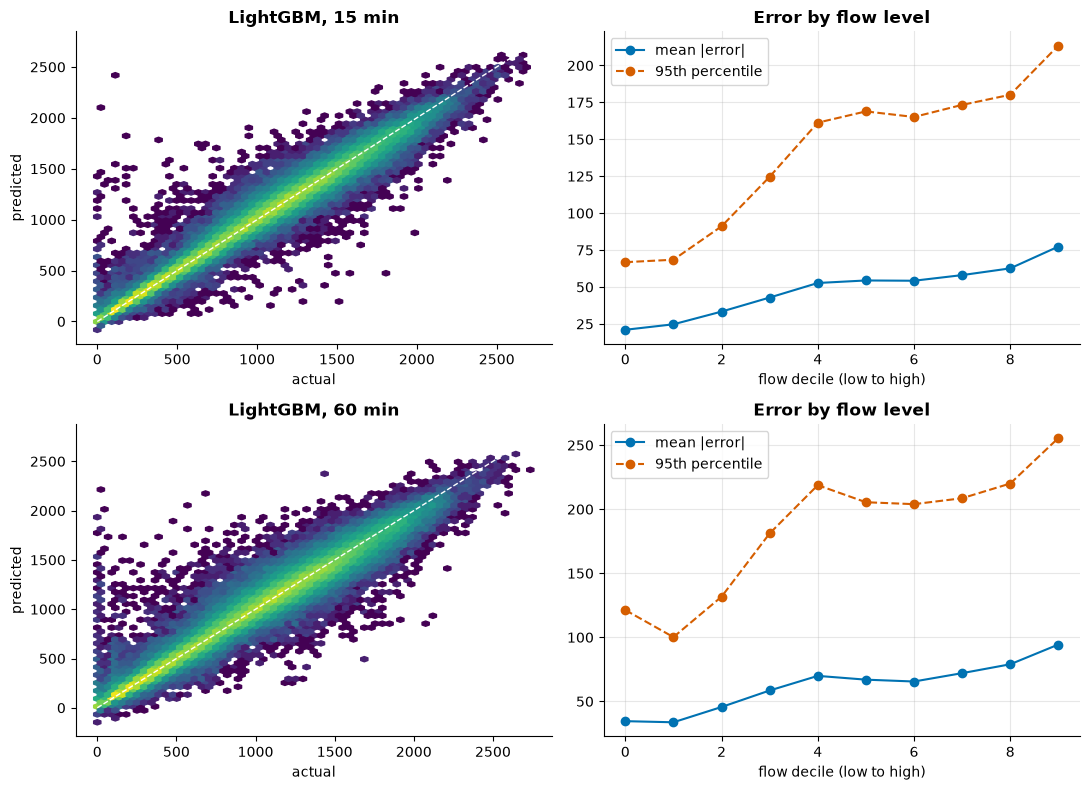

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for r, h in enumerate(ev.HORIZONS):
    top = boards[h].index[0]; key = [k for k, v in NAMES.items() if v == top][0]
    d = ev.load_preds("val", key, h).sample(min(200_000, len(ev.load_table(h, ["val"]))), random_state=0)
    axes[r, 0].hexbin(d["y_raw"], d["pred"], gridsize=60, bins="log", cmap="viridis", mincnt=1)
    lim = [0, max(d["y_raw"].max(), d["pred"].max())]; axes[r, 0].plot(lim, lim, "w--", lw=1)
    axes[r, 0].set_xlabel("actual"); axes[r, 0].set_ylabel("predicted"); axes[r, 0].set_title(f"{top}, {h} min"); axes[r, 0].grid(False)
    bins = pd.qcut(d["y_raw"], 10, duplicates="drop")
    e = (d["y_raw"] - d["pred"]).abs().groupby(bins, observed=True)
    axes[r, 1].plot(range(len(e.mean())), e.mean().to_numpy(), "o-", color="#0072B2", label="mean |error|")
    axes[r, 1].plot(range(len(e.mean())), e.quantile(.95).to_numpy(), "o--", color="#D55E00", label="95th percentile")
    axes[r, 1].set_xlabel("flow decile (low to high)"); axes[r, 1].set_title("Error by flow level"); axes[r, 1].legend()
savefig(fig, "val_residuals")

## 4. Feature drivers (LightGBM) - what the "Feature Drivers" panel in the app shows
Two views on the validation split: LightGBM **gain** importance (how much each feature improved splits) and
**permutation** importance (how much validation error rises when a feature is shuffled; this is the more trustworthy
one when features are correlated). Both are also summed per feature group.

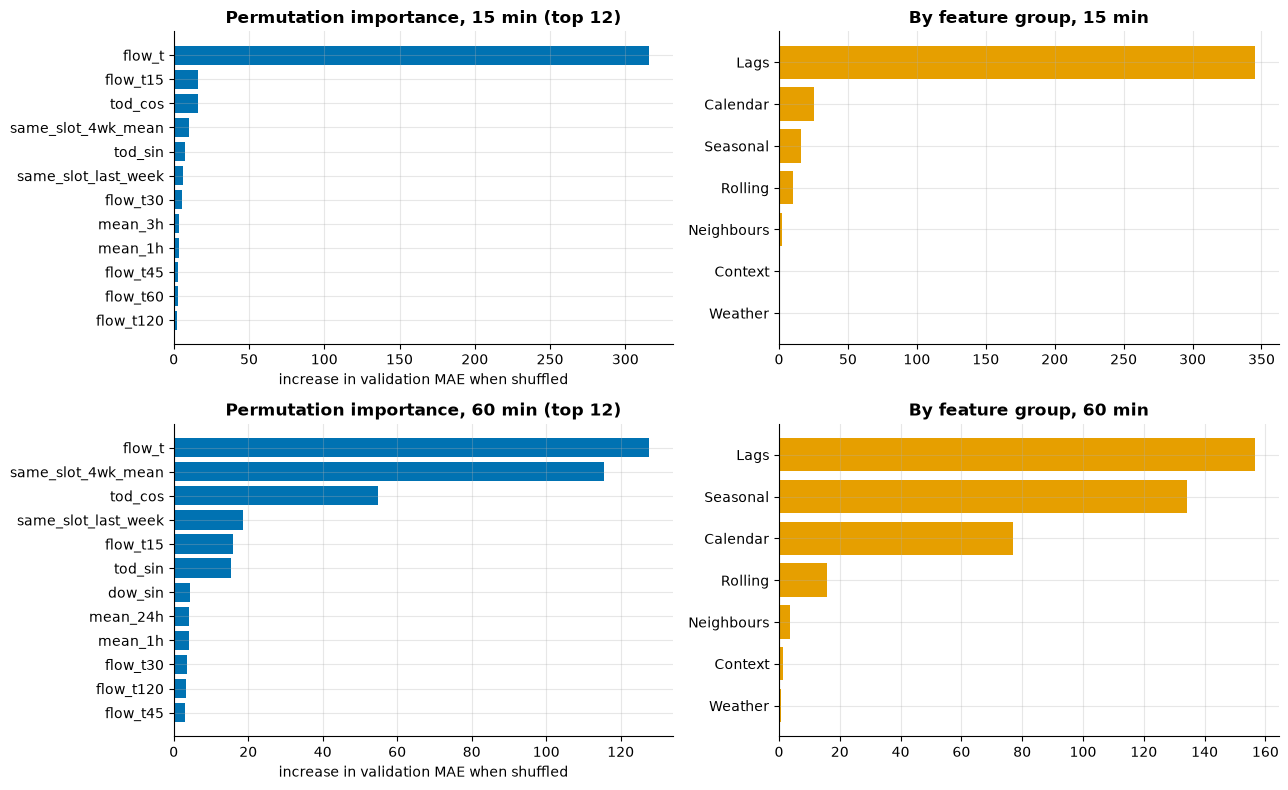

In [7]:
import joblib
from src.features import ALL_FEATURES, FEATURE_GROUPS
gmap = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}
drv = {}
for h in ev.HORIZONS:
    mdl = joblib.load(ev.MODELS_DIR / f"lgbm_h{h}_trainonly.joblib")
    va = ev.load_table(h, ["val"]).sample(min(40_000, 10**9), random_state=0)
    Xv, yv, scv = mo.xy(va)
    base = mo.val_mae_raw(yv, mdl.predict(Xv), scv)
    rng = np.random.default_rng(0)
    perm = {}
    for j, f in enumerate(ALL_FEATURES):
        Xp = Xv.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
        perm[f] = mo.val_mae_raw(yv, mdl.predict(Xp), scv) - base
    gain = pd.Series(mdl.booster_.feature_importance("gain"), index=ALL_FEATURES)
    drv[h] = pd.DataFrame({"gain_share": gain / gain.sum(), "perm_MAE_increase": pd.Series(perm), "group": pd.Series(gmap)})
    drv[h].to_csv(ev.RESULTS / f"feature_drivers_h{h}.csv")
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for r, h in enumerate(ev.HORIZONS):
    d = drv[h].sort_values("perm_MAE_increase").tail(12)
    axes[r, 0].barh(d.index, d["perm_MAE_increase"], color="#0072B2"); axes[r, 0].set_title(f"Permutation importance, {h} min (top 12)")
    axes[r, 0].set_xlabel("increase in validation MAE when shuffled")
    g = drv[h].groupby("group")["perm_MAE_increase"].sum().sort_values()
    axes[r, 1].barh(g.index, g.values, color="#E69F00"); axes[r, 1].set_title(f"By feature group, {h} min")
savefig(fig, "val_feature_drivers")

## 5. Freeze the configuration (Gate G2, step 1)
Writes `results/frozen_config.json`: model, horizon, best parameters and the tree count that the final refit will
reuse. After this file exists, nothing about the models is changed any more; only then do you run the refit
(`python scripts/run_model.py refit --models all --h 15 60 --seeds`) and open notebook 05.

In [8]:
frozen, missing = {}, []
for name in mo.MODELS:
    for h in ev.HORIZONS:
        r = ev.read_best(name, h)
        if r is None:
            missing.append(f"{name} h={h}"); continue
        frozen[f"{name}_h{h}"] = {"params": r["params"], "best_iter": r["best_iter"], "val_MAE": r["val"]["MAE"]}
print("Missing (run them first):", missing or "none")
if not missing:
    (ev.RESULTS / "frozen_config.json").write_text(json.dumps(frozen, indent=2))
    print("Frozen:", len(frozen), "configurations -> results/frozen_config.json")

Missing (run them first): none
Frozen: 18 configurations -> results/frozen_config.json


In [9]:
d = ev.load_preds("val", "ada", 15)
print(d[["y_raw", "pred"]].describe().round(1))
print("bias (pred - actual):", round((d["pred"] - d["y_raw"]).mean(), 2),
      "| corr:", round(d[["y_raw", "pred"]].corr().iloc[0, 1], 3),
      "| distinct preds:", d["pred"].nunique())
print(ev.read_best("ada", 15).keys())

          y_raw      pred
count  350587.0  350587.0
mean      889.4     888.9
std       514.3     505.8
min         0.0       2.4
25%       431.0     434.3
50%       911.0     921.5
75%      1279.0    1276.1
max      2710.0    2564.0
bias (pred - actual): -0.51 | corr: 0.987 | distinct preds: 327070
dict_keys(['model', 'h', 'params', 'best_iter', 'val', 'fit_s_train', 'predict_s_per_100k', 'tune_total_s', 'tune_rows', 'fit_rows', 'smoke'])


In [10]:
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
tr = ev.load_table(15, ["train"]); tr = tr.sample(min(100_000, len(tr)), random_state=0)
vf = ev.load_table(15, ["val"]); va = vf.sample(min(60_000, len(vf)), random_state=0)
Xt, yt, _ = mo.xy(tr); Xv, yv, scv = mo.xy(va)
mae = lambda m: round(mo.val_mae_raw(yv, m.predict(Xv), scv), 2)
print("single tree d8:", mae(DecisionTreeRegressor(max_depth=8, min_samples_leaf=50, random_state=0).fit(Xt, yt)))
for depth in [5, 8]:
    for lr in [0.5, 0.1, 0.02]:
        m = AdaBoostRegressor(DecisionTreeRegressor(max_depth=depth, min_samples_leaf=50), n_estimators=50,
                              learning_rate=lr, loss="linear", random_state=0).fit(Xt, yt)
        print(f"depth={depth} lr={lr}:", mae(m))
m = AdaBoostRegressor(DecisionTreeRegressor(max_depth=8, min_samples_leaf=50), n_estimators=50,
                      learning_rate=0.1, loss="square", random_state=0).fit(Xt, yt)
print("depth=8 lr=0.1 square:", mae(m))

single tree d8: 56.96
depth=5 lr=0.5: 67.28
depth=5 lr=0.1: 61.42
depth=5 lr=0.02: 60.98
depth=8 lr=0.5: 59.81
depth=8 lr=0.1: 55.71
depth=8 lr=0.02: 54.51
depth=8 lr=0.1 square: 56.22
